# Notebook 2 – Numerical Feature Engineering

# Notebook 2 – Numerical Feature Engineering

## Introduction

Numerical Feature Engineering is the process of creating new numerical features or transforming existing numerical features to improve the quality of data.

It helps Machine Learning models identify useful patterns and relationships between numerical values.

### Topics Covered

1. Mathematical Transformations
2. Addition
3. Subtraction
4. Multiplication
5. Division
6. Ratios
7. Percentages
8. Differences
9. Aggregations
10. Log Transformation
11. Square Root Transformation
12. Power Transformation
13. Absolute Difference
14. Relative Difference
15. Rate Features
16. Normalized Features

### Learning Objective

Understand how to create and transform numerical features, when to use each technique, and why these techniques are useful in Machine Learning.



## Step 1 – Import Required Libraries

We use Pandas and NumPy to perform numerical feature engineering.

- Pandas: Used for creating and manipulating DataFrames.
- NumPy: Used for mathematical operations and numerical transformations.
- Matplotlib: Used for visualizing numerical distributions.





In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Step 2 – Create a Sample Dataset

We will use a small sales dataset.

The dataset contains:

- Product Price
- Quantity
- Previous Sales
- Current Sales
- Total Days
- Customer Age

We will create new features using these numerical columns.

In [4]:
data = {
    "Product_Price": [100, 200, 150, 300, 250],
    "Quantity": [2, 3, 4, 2, 5],
    "Previous_Sales": [1000, 1500, 2000, 2500, 3000],
    "Current_Sales": [1200, 1800, 2200, 2000, 3600],
    "Total_Days": [10, 15, 20, 25, 30],
    "Customer_Age": [20, 25, 30, 35, 40]
}

df = pd.DataFrame(data)

df

,Product_Price,Quantity,Previous_Sales,Current_Sales,Total_Days,Customer_Age
0,100,2,1000,1200,10,20
1,200,3,1500,1800,15,25
2,150,4,2000,2200,20,30
3,300,2,2500,2000,25,35
4,250,5,3000,3600,30,40


### Dataset Explanation

Each row represents a sales record.

For example:

- Product_Price = 100
- Quantity = 2
- Previous_Sales = 1000
- Current_Sales = 1200

We can create additional features from these existing columns.

These new features may help a Machine Learning model understand sales patterns better.

In [5]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
df.describe()

Dataset Shape: (5, 6)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Product_Price   5 non-null      int64
 1   Quantity        5 non-null      int64
 2   Previous_Sales  5 non-null      int64
 3   Current_Sales   5 non-null      int64
 4   Total_Days      5 non-null      int64
 5   Customer_Age    5 non-null      int64
dtypes: int64(6)
memory usage: 372.0 bytes

Statistical Summary:


,Product_Price,Quantity,Previous_Sales,Current_Sales,Total_Days,Customer_Age
count,5.000000,5.00000,5.000000,5.000000,5.000000,5.000000
mean,200.000000,3.20000,2000.000000,2160.000000,20.000000,30.000000
std,79.056942,1.30384,790.569415,887.693641,7.905694,7.905694
min,100.000000,2.00000,1000.000000,1200.000000,10.000000,20.000000
25%,150.000000,2.00000,1500.000000,1800.000000,15.000000,25.000000
50%,200.000000,3.00000,2000.000000,2000.000000,20.000000,30.000000
75%,250.000000,4.00000,2500.000000,2200.000000,25.000000,35.000000
max,300.000000,5.00000,3000.000000,3600.000000,30.000000,40.000000


## 1. Mathematical Transformations

### Step 1 – Understand the Concept

Mathematical transformations are operations used to create new numerical features from existing numerical columns.

Common mathematical operations include:

- Addition
- Subtraction
- Multiplication
- Division

### When Should We Use It?

Use mathematical transformations when two or more numerical columns can be combined to create meaningful information.

### Why Should We Use It?

They help create useful features that may reveal relationships between variables.

### Real-World Example

In a shopping application, product price and quantity can be combined to calculate the total purchase amount.

### AI/ML Use Case

In sales prediction, combining product price and quantity can help a model understand the total value of a purchase.



### Step 2 – Demonstrate the Concept

Suppose a customer purchases:

- Product Price = ₹100
- Quantity = 2

Total Purchase Amount:

100 × 2 = ₹200

Instead of providing only price and quantity, we can create a new feature called Total_Amount.






In [6]:
df["Total_Amount"] = df["Product_Price"] * df["Quantity"]

df[["Product_Price", "Quantity", "Total_Amount"]]

,Product_Price,Quantity,Total_Amount
0,100,2,200
1,200,3,600
2,150,4,600
3,300,2,600
4,250,5,1250


### Step 3 – Implementation Explanation

We multiplied Product_Price by Quantity.

The new column Total_Amount represents the total purchase value.

This feature can provide additional information to a sales prediction model.

## 2. Addition

### Step 1 – Understand the Concept

Addition combines two or more numerical features by adding their values.

Formula:

New Feature = Feature A + Feature B

### When Should We Use It?

Use addition when multiple numerical values contribute to a meaningful total.

### Why Should We Use It?

It combines separate values into one feature that represents their total.

### Real-World Example

A customer's total shopping expense can be calculated by adding product expenses and delivery charges.

### AI/ML Use Case

In customer spending prediction, addition can create a Total_Expense feature from different spending categories.


### Step 2 – Demonstrate the Concept

Suppose:

- Product Amount = ₹500
- Delivery Charge = ₹50

Total Expense = 500 + 50 = ₹550

In [7]:
df["Delivery_Charge"] = [50, 40, 60, 30, 70]

df["Total_Expense"] = (
    df["Total_Amount"] + df["Delivery_Charge"]
)

df[["Total_Amount", "Delivery_Charge", "Total_Expense"]]

,Total_Amount,Delivery_Charge,Total_Expense
0,200,50,250
1,600,40,640
2,600,60,660
3,600,30,630
4,1250,70,1320


### Step 3 – Implementation Explanation

We added Total_Amount and Delivery_Charge.

The resulting Total_Expense feature represents the complete expense for each purchase.

Addition is useful when the combined total has business meaning.

## 3. Subtraction

### Step 1 – Understand the Concept

Subtraction calculates the difference between two numerical features.

Formula:

New Feature = Feature A - Feature B

### When Should We Use It?

Use subtraction when we want to measure the gap between two values.

### Why Should We Use It?

It helps identify increases, decreases, profit, loss, and changes over time.

### Real-World Example

A company can calculate its profit by subtracting expenses from revenue.

### AI/ML Use Case

In sales forecasting, subtraction can help a model understand how much sales have increased or decreased.


### Step 2 – Demonstrate the Concept

Suppose:

- Revenue = ₹10,000
- Expense = ₹7,000

Profit = 10,000 - 7,000 = ₹3,000

In [8]:
df["Revenue"] = [10000, 15000, 20000, 18000, 25000]

df["Expense"] = [7000, 9000, 12000, 14000, 15000]

df["Profit"] = df["Revenue"] - df["Expense"]

df[["Revenue", "Expense", "Profit"]]

,Revenue,Expense,Profit
0,10000,7000,3000
1,15000,9000,6000
2,20000,12000,8000
3,18000,14000,4000
4,25000,15000,10000


### Step 3 – Implementation Explanation

We subtracted Expense from Revenue.

The new Profit feature represents the remaining amount after expenses.

This feature can be useful for business profit prediction and financial analysis.

## 4. Multiplication

### Step 1 – Understand the Concept

Multiplication combines numerical features by multiplying their values.

Formula:

New Feature = Feature A × Feature B

### When Should We Use It?

Use multiplication when one value depends on the quantity or scale of another value.

### Why Should We Use It?

It creates a combined feature that represents the overall value of two related variables.

### Real-World Example

Total shopping cost is calculated by multiplying product price by quantity.

### AI/ML Use Case

In sales prediction, multiplication can help create total sales value from unit price and units sold.


### Step 2 – Demonstrate the Concept

Suppose:

- Price per Item = ₹200
- Quantity = 3

Total Amount = 200 × 3 = ₹600

In [9]:
df["Total_Amount"] = (
    df["Product_Price"] * df["Quantity"]
)

df[["Product_Price", "Quantity", "Total_Amount"]]

,Product_Price,Quantity,Total_Amount
0,100,2,200
1,200,3,600
2,150,4,600
3,300,2,600
4,250,5,1250


### Step 3 – Implementation Explanation

We multiplied Product_Price by Quantity.

The resulting Total_Amount feature represents the total value of the products purchased.

Multiplication is useful when two numerical features together represent a meaningful quantity.

## 5. Division

### Step 1 – Understand the Concept

Division calculates the relationship between two numerical values by dividing one feature by another.

Formula:

New Feature = Feature A / Feature B

### When Should We Use It?

Use division when we want to calculate an average, per-unit value, or proportion.

### Why Should We Use It?

It helps convert total values into comparable unit-level measurements.

### Real-World Example

Average price per item can be calculated by dividing total sales by the number of items sold.

### AI/ML Use Case

In business prediction, average spending per customer can help a model understand customer purchasing behavior.

### Important Note

Division by zero is undefined. We must handle zero values before performing division.



### Step 2 – Demonstrate the Concept

Suppose:

- Total Sales = ₹1,000
- Quantity Sold = 5

Average Price = 1000 / 5 = ₹200

In [10]:
df["Average_Price"] = np.where(
    df["Quantity"] != 0,
    df["Total_Amount"] / df["Quantity"],
    np.nan
)

df[["Total_Amount", "Quantity", "Average_Price"]]

,Total_Amount,Quantity,Average_Price
0,200,2,100.0
1,600,3,200.0
2,600,4,150.0
3,600,2,300.0
4,1250,5,250.0


### Step 3 – Implementation Explanation

We divided Total_Amount by Quantity.

The new Average_Price feature represents the average price per item.

We used np.where() to avoid division by zero.

If Quantity is zero, the result is stored as NaN.

## 6. Ratios

### Step 1 – Understand the Concept

A ratio represents the relationship between two numerical values.

Formula:

Ratio = Feature A / Feature B

A ratio helps compare two values even when their scales are different.

### When Should We Use It?

Use ratios when we want to compare two related numerical quantities.

### Why Should We Use It?

Ratios provide meaningful comparisons and help identify proportions between features.

### Real-World Example

A company's debt-to-income ratio compares total debt with total income.

### AI/ML Use Case

In credit risk prediction, financial ratios can help a model understand a customer's financial condition.

### Important Note

The denominator must not be zero. The meaning of a ratio also depends on the units and definitions of both features.



### Step 2 – Demonstrate the Concept

Suppose:

- Total Debt = ₹20,000
- Monthly Income = ₹40,000

Debt-to-Income Ratio:

20,000 / 40,000 = 0.5

The ratio is 0.5, which represents 50%.

In [11]:
df["Debt"] = [20000, 15000, 30000, 25000, 40000]

df["Monthly_Income"] = [40000, 30000, 50000, 50000, 80000]

df["Debt_Income_Ratio"] = np.where(
    df["Monthly_Income"] != 0,
    df["Debt"] / df["Monthly_Income"],
    np.nan
)

df[["Debt", "Monthly_Income", "Debt_Income_Ratio"]]

,Debt,Monthly_Income,Debt_Income_Ratio
0,20000,40000,0.5
1,15000,30000,0.5
2,30000,50000,0.6
3,25000,50000,0.5
4,40000,80000,0.5


### Step 3 – Implementation Explanation

We divided Debt by Monthly_Income.

The new Debt_Income_Ratio feature represents the proportion of income used to measure debt.

This feature can be useful in loan approval and credit risk prediction.

## 7. Percentages

### Step 1 – Understand the Concept

A percentage represents a value as a part of 100.

Formula:

Percentage = (Part / Total) × 100

### When Should We Use It?

Use percentages when we want to express proportions, growth, discounts, or completion rates.

### Why Should We Use It?

Percentages make numerical relationships easier to understand and compare.

### Real-World Example

An online shopping website calculates a discount percentage for each product.

### AI/ML Use Case

In customer analytics, purchase completion percentage can help predict customer conversion behavior.



### Step 2 – Demonstrate the Concept

Suppose:

- Discount Amount = ₹200
- Original Price = ₹1,000

Discount Percentage:

(200 / 1000) × 100 = 20%

In [12]:
df["Discount_Amount"] = [200, 100, 300, 150, 500]

df["Original_Price"] = [1000, 800, 1500, 1200, 2000]

df["Discount_Percentage"] = np.where(
    df["Original_Price"] != 0,
    (df["Discount_Amount"] / df["Original_Price"]) * 100,
    np.nan
)

df[["Discount_Amount", "Original_Price", "Discount_Percentage"]]

,Discount_Amount,Original_Price,Discount_Percentage
0,200,1000,20.0
1,100,800,12.5
2,300,1500,20.0
3,150,1200,12.5
4,500,2000,25.0


### Step 3 – Implementation Explanation

We divided Discount_Amount by Original_Price and multiplied the result by 100.

The new Discount_Percentage feature represents the discount given on each product.

This feature can help analyze customer responses to discounts.

## 8. Differences

### Step 1 – Understand the Concept

A difference feature measures the change between two numerical values.

Formula:

Difference = Current Value - Previous Value

### When Should We Use It?

Use differences when comparing values across two periods or two conditions.

### Why Should We Use It?

It helps identify how much a value has increased or decreased.

### Real-World Example

A business compares this month's sales with last month's sales.

### AI/ML Use Case

In sales forecasting, sales differences can help a model identify changes in business performance.



### Step 2 – Demonstrate the Concept

Suppose:

- Current Sales = ₹1,500
- Previous Sales = ₹1,000

Sales Difference:

1500 - 1000 = ₹500

Sales increased by ₹500.

In [13]:
df["Sales_Difference"] = (
    df["Current_Sales"] - df["Previous_Sales"]
)

df[[
    "Previous_Sales",
    "Current_Sales",
    "Sales_Difference"
]]

,Previous_Sales,Current_Sales,Sales_Difference
0,1000,1200,200
1,1500,1800,300
2,2000,2200,200
3,2500,2000,-500
4,3000,3600,600


### Step 3 – Implementation Explanation

We subtracted Previous_Sales from Current_Sales.

A positive value indicates an increase.

A negative value indicates a decrease.

A zero value indicates no change.

This feature is useful for sales trend analysis.

## 9. Aggregations

### Step 1 – Understand the Concept

Aggregation combines multiple numerical values into summary measurements.

Common aggregation functions include:

- Sum
- Mean
- Median
- Minimum
- Maximum
- Count

### When Should We Use It?

Use aggregation when we need summary information from multiple records or observations.

### Why Should We Use It?

Aggregations reduce large amounts of data into meaningful summary features.

### Real-World Example

An e-commerce company calculates the total spending and average order value for each customer.

### AI/ML Use Case

In customer churn prediction, customer-level spending averages and totals can help identify purchasing behavior.

### Important Note

Aggregated features must use only information available at the prediction time. Using future information can cause data leakage.



### Step 2 – Demonstrate the Concept

Suppose a customer makes three purchases:

- Purchase 1 = ₹100
- Purchase 2 = ₹200
- Purchase 3 = ₹300

Total Spending = 100 + 200 + 300 = ₹600

Average Spending = 600 / 3 = ₹200

In [14]:
customer_data = {
    "Customer_ID": [101, 101, 101, 102, 102, 103],
    "Purchase_Amount": [100, 200, 300, 150, 250, 400]
}

customer_df = pd.DataFrame(customer_data)

customer_df

,Customer_ID,Purchase_Amount
0,101,100
1,101,200
2,101,300
3,102,150
4,102,250
5,103,400


In [15]:
customer_summary = customer_df.groupby("Customer_ID").agg(
    Total_Spending=("Purchase_Amount", "sum"),
    Average_Spending=("Purchase_Amount", "mean"),
    Maximum_Spending=("Purchase_Amount", "max"),
    Minimum_Spending=("Purchase_Amount", "min"),
    Purchase_Count=("Purchase_Amount", "count")
).reset_index()

customer_summary

,Customer_ID,Total_Spending,Average_Spending,Maximum_Spending,Minimum_Spending,Purchase_Count
0,101,600,200.0,300,100,3
1,102,400,200.0,250,150,2
2,103,400,400.0,400,400,1


### Step 3 – Implementation Explanation

We used groupby() to group purchase records by Customer_ID.

Then we applied different aggregation functions:

- sum: Calculates total spending.
- mean: Calculates average spending.
- max: Finds the highest purchase.
- min: Finds the lowest purchase.
- count: Counts the number of purchases.

These features summarize customer purchasing behavior.

They are useful in customer segmentation and customer churn prediction.

## 10. Log Transformation

### Step 1 – Understand the Concept

Log transformation applies a logarithmic function to numerical values.

It is commonly used to reduce right-skewness in numerical data.

Example:

Log Transformation = log(1 + X)

In Python, we can use np.log1p().

### When Should We Use It?

Use log transformation when numerical data contains:

- Highly skewed values.
- Large differences between small and large values.
- Long right tails in the distribution.

### Why Should We Use It?

It reduces the impact of very large values and can make a skewed distribution more manageable for certain Machine Learning algorithms.

### Real-World Example

Income data may contain many people with lower incomes and a small number of people with extremely high incomes.

### AI/ML Use Case

Log transformation can be useful in house price prediction, income prediction, and sales prediction.

### Important Note

Log transformation requires values greater than zero when using np.log(). np.log1p() accepts values greater than -1. For non-negative features, it is commonly used as log(1 + X).



### Step 2 – Demonstrate the Concept

Suppose the sales values are:

100, 500, 1000, 5000, 50000

The large value 50000 is much greater than the other values.

Log transformation reduces the scale difference between these values.

In [16]:
df["Log_Sales"] = np.log1p(df["Current_Sales"])

df[["Current_Sales", "Log_Sales"]]

,Current_Sales,Log_Sales
0,1200,7.090910
1,1800,7.496097
2,2200,7.696667
3,2000,7.601402
4,3600,8.188967


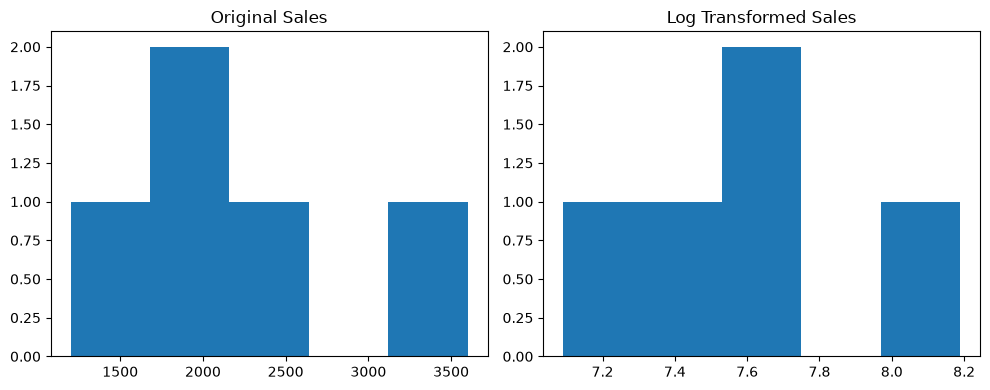

In [17]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(df["Current_Sales"], bins=5)
plt.title("Original Sales")

plt.subplot(1, 2, 2)
plt.hist(df["Log_Sales"], bins=5)
plt.title("Log Transformed Sales")

plt.tight_layout()
plt.show()

### Step 3 – Implementation Explanation

We used np.log1p() to transform Current_Sales.

It applies log(1 + x) to each value.

The transformed values have a smaller numerical scale.

Log transformation can reduce skewness, but it does not guarantee a normal distribution.

## 11. Square Root Transformation

### Step 1 – Understand the Concept

Square root transformation applies the square root function to numerical values.

Formula:

New Feature = √X

In Python, we use np.sqrt().

### When Should We Use It?

Use square root transformation when numerical data is moderately right-skewed.

It is also commonly useful for non-negative count data.

### Why Should We Use It?

It reduces the differences between large and small values, usually less aggressively than log transformation.

### Real-World Example

A company may analyze the number of orders received each day.

### AI/ML Use Case

Square root transformation can be useful when preparing count-based features for certain Machine Learning models.

### Important Note

Square root transformation requires non-negative values.



### Step 2 – Demonstrate the Concept

Suppose:

- 4 → √4 = 2
- 16 → √16 = 4
- 64 → √64 = 8
- 100 → √100 = 10

Large values become smaller after transformation.

In [18]:
df["Square_Root_Sales"] = np.sqrt(df["Current_Sales"])

df[["Current_Sales", "Square_Root_Sales"]]

,Current_Sales,Square_Root_Sales
0,1200,34.641016
1,1800,42.426407
2,2200,46.904158
3,2000,44.721360
4,3600,60.000000


### Step 3 – Implementation Explanation

We used np.sqrt() to calculate the square root of Current_Sales.

The new Square_Root_Sales feature contains the transformed values.

This technique can reduce the effect of large values and is suitable for non-negative data.

## 12. Power Transformation

### Step 1 – Understand the Concept

Power transformation changes numerical values by raising them to a specified power.

Formula:

New Feature = Xⁿ

Examples:

- Square: X²
- Cube: X³

### When Should We Use It?

Use power transformations when we want to create nonlinear relationships or change the distribution of numerical features.

### Why Should We Use It?

It can help a model capture patterns that are not represented by the original numerical feature.

### Real-World Example

A business may analyze how advertising expenditure relates to sales when the relationship is not linear.

### AI/ML Use Case

Polynomial features can help linear regression models represent nonlinear relationships.

### Important Note

Power transformations can increase skewness and make large values even larger. Select the power carefully and check the resulting distribution.


### Step 2 – Demonstrate the Concept

Suppose X = 3.

Square:

3² = 9

Cube:

3³ = 27

The original value is transformed into new numerical values.

In [19]:
df["Sales_Squared"] = df["Current_Sales"] ** 2

df["Sales_Cubed"] = df["Current_Sales"] ** 3

df[[
    "Current_Sales",
    "Sales_Squared",
    "Sales_Cubed"
]]

,Current_Sales,Sales_Squared,Sales_Cubed
0,1200,1440000,1728000000
1,1800,3240000,5832000000
2,2200,4840000,10648000000
3,2000,4000000,8000000000
4,3600,12960000,46656000000


### Step 3 – Implementation Explanation

We created two new features:

- Sales_Squared: Current_Sales raised to power 2.
- Sales_Cubed: Current_Sales raised to power 3.

These features can help models capture nonlinear patterns.

However, the transformed features should be checked for very large values and possible numerical issues.

## 13. Absolute Difference

### Step 1 – Understand the Concept

Absolute difference measures the distance between two numerical values without considering which value is larger.

Formula:

Absolute Difference = |Feature A - Feature B|

In Python, we use np.abs().

### When Should We Use It?

Use absolute difference when we only care about the size of the difference, not whether it is positive or negative.

### Why Should We Use It?

It represents the magnitude of the gap between two values.

### Real-World Example

A company compares the actual sales with the expected sales.

### AI/ML Use Case

In prediction analysis, absolute differences can help measure the gap between actual and predicted values.


### Step 2 – Demonstrate the Concept

Suppose:

- Expected Sales = 1000
- Actual Sales = 800

Absolute Difference:

|800 - 1000| = 200

The absolute difference is 200.

Even if the actual sales were 1200, the absolute difference would still be 200.

In [20]:
df["Expected_Sales"] = [1000, 1500, 2000, 2500, 3000]

df["Actual_Sales"] = [800, 1800, 1900, 2800, 2700]

df["Absolute_Difference"] = np.abs(
    df["Actual_Sales"] - df["Expected_Sales"]
)

df[[
    "Expected_Sales",
    "Actual_Sales",
    "Absolute_Difference"
]]

,Expected_Sales,Actual_Sales,Absolute_Difference
0,1000,800,200
1,1500,1800,300
2,2000,1900,100
3,2500,2800,300
4,3000,2700,300


### Step 3 – Implementation Explanation

We subtracted Expected_Sales from Actual_Sales and applied np.abs().

The resulting Absolute_Difference feature always contains a non-negative value.

It measures how far actual sales are from expected sales without indicating the direction of the difference.

## 14. Relative Difference

### Step 1 – Understand the Concept

Relative difference measures the difference between two values in relation to a reference value.

Formula:

Relative Difference = (Current Value - Previous Value) / Previous Value

### When Should We Use It?

Use relative difference when comparing changes across values with different scales.

### Why Should We Use It?

It expresses a change relative to the previous value, making comparisons between different-sized values easier.

### Real-World Example

A business compares monthly sales growth with the previous month.

### AI/ML Use Case

Relative difference can be used in sales forecasting and financial prediction to represent proportional changes.

### Important Note

The reference value must not be zero. A negative reference value also requires careful interpretation.



### Step 2 – Demonstrate the Concept

Suppose:

- Previous Sales = 1000
- Current Sales = 1200

Relative Difference:

(1200 - 1000) / 1000 = 0.2

Percentage Change:

0.2 × 100 = 20%

Sales increased by 20%.

In [21]:
df["Relative_Difference"] = np.where(
    df["Previous_Sales"] != 0,
    (
        df["Current_Sales"] - df["Previous_Sales"]
    ) / df["Previous_Sales"],
    np.nan
)

df["Relative_Difference_Percentage"] = (
    df["Relative_Difference"] * 100
)

df[[
    "Previous_Sales",
    "Current_Sales",
    "Relative_Difference",
    "Relative_Difference_Percentage"
]]

,Previous_Sales,Current_Sales,Relative_Difference,Relative_Difference_Percentage
0,1000,1200,0.2,20.0
1,1500,1800,0.2,20.0
2,2000,2200,0.1,10.0
3,2500,2000,-0.2,-20.0
4,3000,3600,0.2,20.0


### Step 3 – Implementation Explanation

We calculated the difference between Current_Sales and Previous_Sales.

Then we divided the difference by Previous_Sales.

The Relative_Difference feature represents the proportional change.

The Relative_Difference_Percentage feature represents the same change as a percentage.

Positive values indicate growth, while negative values indicate a decrease.

## 15. Rate Features

### Step 1 – Understand the Concept

A rate feature measures how much of something happens per unit of time, distance, quantity, or another measurement.

Formula:

Rate = Total Amount / Total Units

### When Should We Use It?

Use rate features when we want to measure the speed, frequency, or amount of an activity per unit.

### Why Should We Use It?

Rate features help compare activities across different time periods or quantities.

### Real-World Example

A delivery company calculates the number of deliveries completed per day.

### AI/ML Use Case

In business prediction, average sales per day can help a model understand sales performance over time.

### Important Note

The denominator must be meaningful and non-zero. Ensure that the time period or unit is consistent across records.


### Step 2 – Demonstrate the Concept

Suppose:

- Total Sales = ₹5,000
- Total Days = 10

Sales Per Day:

5000 / 10 = ₹500

The sales rate is ₹500 per day.

In [22]:
df["Sales_Per_Day"] = np.where(
    df["Total_Days"] != 0,
    df["Current_Sales"] / df["Total_Days"],
    np.nan
)

df[[
    "Current_Sales",
    "Total_Days",
    "Sales_Per_Day"
]]

,Current_Sales,Total_Days,Sales_Per_Day
0,1200,10,120.0
1,1800,15,120.0
2,2200,20,110.0
3,2000,25,80.0
4,3600,30,120.0


### Step 3 – Implementation Explanation

We divided Current_Sales by Total_Days.

The new Sales_Per_Day feature represents average sales per day.

This feature can help compare sales performance across different time periods.

## 16. Normalized Features

### Step 1 – Understand the Concept

Normalization is a scaling technique that changes numerical values to a common range.

One common method is Min-Max Normalization.

Formula:

X_normalized = (X - X_min) / (X_max - X_min)

This usually scales values between 0 and 1.

### When Should We Use It?

Use normalization when numerical features have different scales and an algorithm is sensitive to feature magnitude.

### Why Should We Use It?

It prevents features with larger numerical ranges from dominating distance-based or gradient-based calculations simply because of their scale.

### Real-World Example

A customer dataset may contain:

- Age: 18 to 70
- Annual Income: 20,000 to 500,000
- Purchase Count: 1 to 100

These features have very different ranges.

### AI/ML Use Case

Normalization is useful for algorithms such as K-Nearest Neighbors, Neural Networks, and some gradient-based models.

### Important Note

Fit the scaler using training data only. Use the same fitted scaler to transform validation and test data. This prevents data leakage.



### Step 2 – Demonstrate the Concept

Suppose a feature contains:

10, 20, 30, 40, 50

Minimum Value = 10

Maximum Value = 50

For the value 30:

Normalized Value:

(30 - 10) / (50 - 10)

= 20 / 40

= 0.5

The normalized value is 0.5.

In [23]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

df["Normalized_Sales"] = scaler.fit_transform(
    df[["Current_Sales"]]
)

df[["Current_Sales", "Normalized_Sales"]]

,Current_Sales,Normalized_Sales
0,1200,0.000000
1,1800,0.250000
2,2200,0.416667
3,2000,0.333333
4,3600,1.000000


### Step 3 – Implementation Explanation

We imported MinMaxScaler from Scikit-learn.

The scaler calculates the minimum and maximum values and transforms the feature into the range 0 to 1.

The new Normalized_Sales feature contains scaled values.

For this demonstration, we fitted the scaler on the complete sample dataset.

In a real Machine Learning project, we must split the data first, fit the scaler only on training data, and transform validation and test data using that fitted scaler.

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

X = df[["Current_Sales"]]
y = df["Customer_Age"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Training Data:")
print(X_train_scaled)

print("\nTesting Data:")
print(X_test_scaled)

Training Data:
[[1.        ]
 [0.41666667]
 [0.        ]
 [0.33333333]]

Testing Data:
[[0.25]]


### Why Do We Split Before Scaling?

We split the dataset into training and testing data before fitting the scaler.

- fit_transform(): Learns scaling information from training data and transforms it.
- transform(): Uses the same learned information to transform test data.

This prevents the scaler from learning information from the test dataset.

This is an important step in building reliable Machine Learning models.

## 17. Comparing Numerical Transformations

Different numerical transformations are useful for different purposes.

### Why Should We Compare Them?

Each transformation changes numerical data in a different way.

Comparing them helps us select a suitable technique based on the data distribution and Machine Learning problem.

In [25]:
comparison_df = pd.DataFrame({
    "Original": df["Current_Sales"],
    "Log": np.log1p(df["Current_Sales"]),
    "Square_Root": np.sqrt(df["Current_Sales"]),
    "Squared": df["Current_Sales"] ** 2
})

comparison_df

,Original,Log,Square_Root,Squared
0,1200,7.090910,34.641016,1440000
1,1800,7.496097,42.426407,3240000
2,2200,7.696667,46.904158,4840000
3,2000,7.601402,44.721360,4000000
4,3600,8.188967,60.000000,12960000


## 18. Practical Numerical Feature Engineering Workflow

### Step 1 – Understand the Concept

A numerical feature engineering workflow is a sequence of steps used to create useful numerical features from raw data.

### Workflow

1. Identify numerical columns.
2. Understand the meaning of each feature.
3. Check missing and zero values.
4. Identify useful mathematical relationships.
5. Create new numerical features.
6. Apply suitable transformations.
7. Check feature distributions.
8. Handle scaling when required.
9. Avoid data leakage.
10. Evaluate whether the new features improve the model.

### Why Is This Workflow Important?

It helps us create meaningful features systematically instead of applying mathematical operations without understanding the data.

In [26]:
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns

print("Numerical Columns:")
print(list(numerical_columns))

Numerical Columns:
['Product_Price', 'Quantity', 'Previous_Sales', 'Current_Sales', 'Total_Days', 'Customer_Age', 'Total_Amount', 'Delivery_Charge', 'Total_Expense', 'Revenue', 'Expense', 'Profit', 'Average_Price', 'Debt', 'Monthly_Income', 'Debt_Income_Ratio', 'Discount_Amount', 'Original_Price', 'Discount_Percentage', 'Sales_Difference', 'Log_Sales', 'Square_Root_Sales', 'Sales_Squared', 'Sales_Cubed', 'Expected_Sales', 'Actual_Sales', 'Absolute_Difference', 'Relative_Difference', 'Relative_Difference_Percentage', 'Sales_Per_Day', 'Normalized_Sales']


In [27]:
print("Missing Values:")
print(df[numerical_columns].isnull().sum())

print("\nZero Values:")
print((df[numerical_columns] == 0).sum())

Missing Values:
Product_Price                     0
Quantity                          0
Previous_Sales                    0
Current_Sales                     0
Total_Days                        0
Customer_Age                      0
Total_Amount                      0
Delivery_Charge                   0
Total_Expense                     0
Revenue                           0
Expense                           0
Profit                            0
Average_Price                     0
Debt                              0
Monthly_Income                    0
Debt_Income_Ratio                 0
Discount_Amount                   0
Original_Price                    0
Discount_Percentage               0
Sales_Difference                  0
Log_Sales                         0
Square_Root_Sales                 0
Sales_Squared                     0
Sales_Cubed                       0
Expected_Sales                    0
Actual_Sales                      0
Absolute_Difference               0
Relative_Dif

In [28]:
final_features = df[[
    "Product_Price",
    "Quantity",
    "Total_Amount",
    "Total_Expense",
    "Profit",
    "Average_Price",
    "Debt_Income_Ratio",
    "Discount_Percentage",
    "Sales_Difference",
    "Log_Sales",
    "Square_Root_Sales",
    "Sales_Squared",
    "Absolute_Difference",
    "Relative_Difference",
    "Sales_Per_Day",
    "Normalized_Sales"
]]

final_features

,Product_Price,Quantity,Total_Amount,Total_Expense,Profit,Average_Price,Debt_Income_Ratio,Discount_Percentage,Sales_Difference,Log_Sales,Square_Root_Sales,Sales_Squared,Absolute_Difference,Relative_Difference,Sales_Per_Day,Normalized_Sales
0,100,2,200,250,3000,100.0,0.5,20.0,200,7.090910,34.641016,1440000,200,0.2,120.0,0.000000
1,200,3,600,640,6000,200.0,0.5,12.5,300,7.496097,42.426407,3240000,300,0.2,120.0,0.250000
2,150,4,600,660,8000,150.0,0.6,20.0,200,7.696667,46.904158,4840000,100,0.1,110.0,0.416667
3,300,2,600,630,4000,300.0,0.5,12.5,-500,7.601402,44.721360,4000000,300,-0.2,80.0,0.333333
4,250,5,1250,1320,10000,250.0,0.5,25.0,600,8.188967,60.000000,12960000,300,0.2,120.0,1.000000


# Final Conclusion

In this notebook, we learned different numerical feature engineering techniques.

### What We Learned

- Mathematical transformations help create new features.
- Addition combines numerical values.
- Subtraction calculates differences.
- Multiplication creates combined numerical values.
- Division calculates per-unit values.
- Ratios compare related numerical features.
- Percentages represent proportions.
- Differences measure changes between values.
- Aggregations summarize multiple records.
- Log transformation reduces strong right-skewness.
- Square root transformation reduces the scale of non-negative values.
- Power transformation creates nonlinear features.
- Absolute difference measures the magnitude of a gap.
- Relative difference measures proportional changes.
- Rate features measure values per unit.
- Normalization scales numerical features to a common range.

### Key Learning

Not every mathematical transformation is useful for every dataset.

We should understand the data, identify meaningful relationships, select appropriate techniques, and evaluate whether the newly created features improve Machine Learning performance.

### Important Machine Learning Practices

1. Handle division by zero.
2. Check the distribution of transformed features.
3. Avoid unnecessary features.
4. Prevent data leakage.
5. Fit learned transformations using training data only.
6. Evaluate the impact of new features on model performance.

Numerical Feature Engineering helps convert raw numerical data into meaningful features that can improve Machine Learning models.